# 5 — Application Out-of-Time (OOT) et backtesting

Application de la chaîne réglementaire finale (**Grille PDO → CHR → PD calibrée & réglementaire → Échelle maître**) à la base Out-of-Time, suivie du backtesting complet (chapitre 9) :
1. Préparation de la base OOT à l'identique du développement (périmètre, dossiers joints, segmentation, valeurs impossibles, *feature engineering*).
2. Scoring PDO, affectation des CHR, des PD (meilleure estimation et PD réglementaire avec MoC A + C) et des grades de l'échelle maître.
3. Backtesting du pouvoir discriminant (9.1) : AUC, Gini (score continu et CHR, IC 95 % bootstrap par client), KS et suivi mensuel.
4. Stabilité de la population (9.3) : PSI sur les CHR et CSI sur chaque variable du modèle.
5. Contrôle des CHR sur l'OOT : monotonie, hétérogénéité inter-CHR, stabilité mensuelle.
6. Backtesting de la calibration (9.2) : Brier & décomposition de Murphy, test de Jeffreys par classe, diagramme de calibration.

## 1. Paramètres et chargement des artefacts du modèle final

In [5]:
# Cellule 1 — paramètres et chargement des artefacts du modèle final
from pathlib import Path
import matplotlib.pyplot as plt
import polars as pl
from utils import backtesting, binning, calibrage, chr as chrm, exploration, models, scorecard

pl.Config.set_tbl_rows(-1); pl.Config.set_tbl_cols(-1); pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_column_data_types(True)

CODE = "SB"
SEGMENT_CIBLE = "SB_mono_avec_eng"
ID, TARGET, DATE = "gdt", "ddefaut_ndb", "datdelhis"
SCORE_REF, ODDS_REF, PDO = 600, 50, 20

# Chemin de la base OOT brute (.sas7bdat, .sas7bdat.gz ou .parquet) et cache parquet
SOURCE_OOT = Path("data/_01_99__ensai_par_oot_final.sas7bdat")
CACHE_OOT = Path("data/processed/base_oot_brute.parquet")

regles_modele = binning.charger_regles(f"outputs/scorecard/regles_modele_{CODE}.json")
grille = pl.read_excel(f"outputs/scorecard/grille_{CODE}.xlsx", sheet_name=f"{CODE}_Grille")
regle_chr = binning.charger_regles(f"outputs/chr/regle_chr_{CODE}.json")["chr"]
chr_train_ref = pl.read_excel(f"outputs/chr/chr_{CODE}.xlsx", sheet_name=f"{CODE}_CHR_train")
numeros_chr = dict(zip(chr_train_ref["intervalle_score"], chr_train_ref["chr"]))
pd_finales = pl.read_parquet("outputs/quantification/pd_finales.parquet")

# Bases de référence (développement : apprentissage & test)
ref_modele = pl.read_parquet(f"data/processed/base_modele_{CODE}.parquet")
ref_chr = pl.read_parquet(f"data/processed/base_chr_{CODE}.parquet")
ref_train = ref_chr.filter(pl.col("echantillon") == "train")
ref_test = ref_chr.filter(pl.col("echantillon") == "test")
print(f"Artéfacts chargés pour {CODE} : {len(regles_modele)} variables | {len(numeros_chr)} CHR")

Artéfacts chargés pour SB : 10 variables | 5 CHR


## 2. Préparation de la base OOT (périmètre, segmentation, feature engineering)

In [6]:
# Cellule 2 — chargement, périmètre, unification des joints, segmentation et feature engineering
oot_brute = backtesting.charger_base_brute(SOURCE_OOT, cache=CACHE_OOT, date=DATE)
print(f"Base OOT brute : {oot_brute.height:,} lignes | dates : {oot_brute[DATE].unique().sort().to_list()}")

oot, suivi_oot = backtesting.preparer_oot(oot_brute, TARGET, segment_cible=SEGMENT_CIBLE)
print("=== Suivi périmètre OOT"); print(suivi_oot["perimetre"])
print("=== Répartition par segment OOT"); print(suivi_oot["segments"])
print("=== Valeurs impossibles neutralisées"); print(suivi_oot["impossibles"])
print(f"Base OOT {CODE} prête : {oot.height:,} lignes | {oot[ID].n_unique():,} clients | taux défaut : {oot[TARGET].mean():.3%}")

Base OOT brute : 573,253 lignes | dates : [datetime.date(2024, 12, 1)]
=== Suivi périmètre OOT
shape: (3, 4)
┌─────────────────────────────────┬────────┬──────────┬─────────────┐
│ etape                           ┆ n      ┆ n_defaut ┆ taux_defaut │
╞═════════════════════════════════╪════════╪══════════╪═════════════╡
│ base initiale                   ┆ 573253 ┆ 7317.0   ┆ 0.012764    │
│ exclusion : défaut à date (NBJ… ┆ 567670 ┆ 5394.0   ┆ 0.009502    │
│ exclusion : mineurs (< 18 ans)  ┆ 488048 ┆ 5300.0   ┆ 0.01086     │
└─────────────────────────────────┴────────┴──────────┴─────────────┘
=== Répartition par segment OOT
shape: (3, 4)
┌──────────────────┬────────┬──────────┬─────────────┐
│ segment          ┆ n      ┆ n_defaut ┆ taux_defaut │
╞══════════════════╪════════╪══════════╪═════════════╡
│ SA_mono_sans_eng ┆ 165921 ┆ 1099.0   ┆ 0.006624    │
│ SB_mono_avec_eng ┆ 227799 ┆ 3671.0   ┆ 0.016115    │
│ SM_multi         ┆ 94328  ┆ 530.0    ┆ 0.005619    │
└──────────────────┴─────

## 3. Application de la chaîne complète (`Score PDO → CHR → PD & Grade`)

In [ ]:
# Cellule 3 — scoring PDO, affectation CHR, PD calibrée / réglementaire et grade échelle maître
oot_score = backtesting.appliquer_chaine_scoring(
    oot, grille, regles_modele, regle_chr, pd_finales,
    segment=CODE, score_ref=SCORE_REF, odds_ref=ODDS_REF, pdo=PDO, numeros_chr=numeros_chr
)
print(f"Lignes scorées : {oot_score.height:,} | Score PDO : min={oot_score['score'].min():.0f}, médiane={oot_score['score'].median():.0f}, max={oot_score['score'].max():.0f}")
print("Valeurs manquantes après scoring :")
print(oot_score.select("score", "chr", "pd_estimee", "pd_finale", "grade").null_count())

## 4. Backtesting du pouvoir discriminant (9.1)

shape: (3, 11)
┌─────────────┬────────┬──────────┬─────────────┬───────────┬────────────┬──────────┬──────────┬────────────────┬─────────────┬──────────────┐
│ echantillon ┆ n      ┆ n_defaut ┆ taux_defaut ┆ auc_score ┆ gini_score ┆ ks_score ┆ gini_chr ┆ perte_gini_pts ┆ gini_ic_bas ┆ gini_ic_haut │
╞═════════════╪════════╪══════════╪═════════════╪═══════════╪════════════╪══════════╪══════════╪════════════════╪═════════════╪══════════════╡
│ Train       ┆ 88629  ┆ 1091     ┆ 0.01231     ┆ 0.920697  ┆ 0.841393   ┆ 0.694294 ┆ 0.81354  ┆ 2.7853         ┆ 0.825499    ┆ 0.856657     │
│ Test        ┆ 37996  ┆ 470      ┆ 0.01237     ┆ 0.91238   ┆ 0.824759   ┆ 0.700359 ┆ 0.804232 ┆ 2.052693       ┆ 0.795802    ┆ 0.850318     │
│ OOT         ┆ 227799 ┆ 3671     ┆ 0.016115    ┆ 0.892239  ┆ 0.784477   ┆ 0.634094 ┆ 0.752475 ┆ 3.200162       ┆ 0.775417    ┆ 0.792947     │
└─────────────┴────────┴──────────┴─────────────┴───────────┴────────────┴──────────┴──────────┴────────────────┴─────────────┴

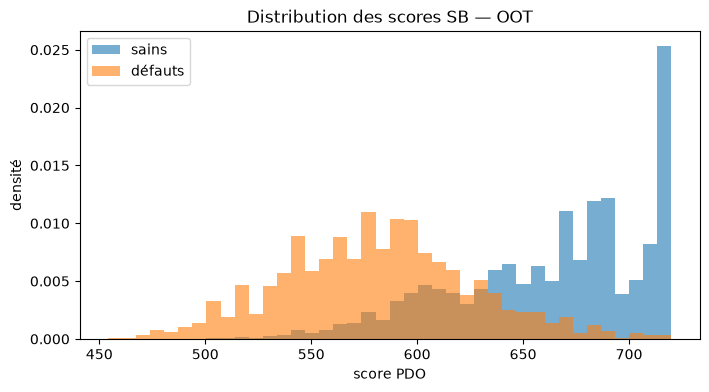

shape: (10, 7)
┌─────────┬───────────┬───────────┬───────┬──────────┬─────────────┬──────────────────────┐
│ tranche ┆ score_min ┆ score_max ┆ n     ┆ n_defaut ┆ taux_defaut ┆ part_defauts_cumulee │
╞═════════╪═══════════╪═══════════╪═══════╪══════════╪═════════════╪══════════════════════╡
│ 1       ┆ 454.0     ┆ 595.0     ┆ 22779 ┆ 2302.0   ┆ 0.101058    ┆ 0.627077             │
│ 2       ┆ 595.0     ┆ 619.0     ┆ 22780 ┆ 656.0    ┆ 0.028797    ┆ 0.805775             │
│ 3       ┆ 619.0     ┆ 641.0     ┆ 22780 ┆ 371.0    ┆ 0.016286    ┆ 0.906837             │
│ 4       ┆ 641.0     ┆ 658.0     ┆ 22780 ┆ 157.0    ┆ 0.006892    ┆ 0.949605             │
│ 5       ┆ 658.0     ┆ 673.0     ┆ 22780 ┆ 79.0     ┆ 0.003468    ┆ 0.971125             │
│ 6       ┆ 673.0     ┆ 684.0     ┆ 22780 ┆ 38.0     ┆ 0.001668    ┆ 0.981476             │
│ 7       ┆ 684.0     ┆ 691.0     ┆ 22780 ┆ 29.0     ┆ 0.001273    ┆ 0.989376             │
│ 8       ┆ 691.0     ┆ 709.0     ┆ 22780 ┆ 22.0     ┆ 0.000966  

In [8]:
# Cellule 4 — comparaison Train / Test / OOT (AUC, Gini, KS, perte de Gini) et suivi mensuel
disc_globale = backtesting.backtest_discrimination(
    {"Train": ref_train, "Test": ref_test, "OOT": oot_score},
    target=TARGET, score_col="score", chr_col="chr", id_col=ID, n_bootstrap=1000
)
print(disc_globale)

disc_mensuelle = backtesting.discrimination_mensuelle(oot_score, TARGET, DATE)
print(disc_mensuelle)

# Distribution des scores et concentration des défauts par tranche de score sur l'OOT
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(oot_score.filter(pl.col(TARGET) == 0)["score"], bins=40, alpha=0.6, density=True, label="sains")
ax.hist(oot_score.filter(pl.col(TARGET) == 1)["score"], bins=40, alpha=0.6, density=True, label="défauts")
ax.set(xlabel="score PDO", ylabel="densité", title=f"Distribution des scores {CODE} — OOT"); ax.legend(); plt.show()

print(scorecard.taux_par_tranche(oot_score["score"], oot_score[TARGET], n_tranches=10))
# Courbes ROC et Précision-Rappel sur l'OOT (score continu vs CHR)
SCORES_OOT = {"Score PDO": -oot_score["score"].to_numpy(), "CHR": oot_score["chr"].to_numpy()}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
models.courbes_roc(oot_score[TARGET], SCORES_OOT, titre=f"Courbes ROC {CODE} — OOT", ax=axes[0])
models.courbes_pr(oot_score[TARGET], SCORES_OOT, titre=f"Courbes Précision-Rappel {CODE} — OOT", ax=axes[1])
plt.tight_layout(); plt.show()


## 4 bis. Cascade de simplification et discrimination intra-CHR (OOT)

In [ ]:
# Cellule 4 bis — AUC-ROC / Gini / AUC-PR intra-CHR et cascade de simplification sur l'OOT
scores_intra_oot = {"Score PDO": -oot_score["score"].to_numpy()}
etapes_oot = []

chemin_xgb_model = Path(f"outputs/scorecard/xgb_opt_{CODE}.json")
if chemin_xgb_model.exists():
    import xgboost as xgb
    regles_bin = binning.charger_regles(f"outputs/scorecard/regles_{CODE}.json")
    sel_bin = pl.read_excel(f"outputs/binning_{CODE}.xlsx", sheet_name=f"{CODE}_Selection")
    vars_xgb = sel_bin.filter(pl.col("statut") == "retenue")["variable"].to_list()
    xgb_oot = xgb.XGBClassifier(); xgb_oot.load_model(chemin_xgb_model)
    X_oot_brut = models.matrice_xgb(
        oot, vars_xgb, regles_bin, TARGET, "brut",
        ref=ref_modele.filter(pl.col("echantillon") == "train")
    )
    pred_xgb_oot = xgb_oot.predict_proba(X_oot_brut)[:, 1]
    scores_intra_oot["XGBoost brut optimisé"] = pred_xgb_oot
    etapes_oot.append(("0. XGBoost brut optimisé", pred_xgb_oot))

etapes_oot += [
    ("1. Grille PDO finale", -oot_score["score"].to_numpy()),
    (f"2. CHR ({len(numeros_chr)} classes)", oot_score["chr"].to_numpy()),
]

cascade_oot = models.cascade_simplification(oot_score[TARGET], etapes_oot)
print("=== Cascade de simplification — OOT")
print(cascade_oot)

intra_chr_oot = chrm.discrimination_intra_chr(oot_score, TARGET, "chr", scores_intra_oot)
print("=== Discrimination résiduelle intra-CHR — OOT")
print(intra_chr_oot)


## 5. Stabilité de la population : PSI et CSI (9.3)

In [9]:
# Cellule 5 — PSI sur les CHR et CSI sur chaque variable du modèle (Train -> OOT)
psi_val, psi_detail = backtesting.psi_entre_echantillons(ref_train, oot_score, "chr")
print(f"PSI global (Train -> OOT sur les CHR) = {psi_val:.4f} ({backtesting._verdict_psi(psi_val)})")
print(psi_detail)

csi_synthese, csi_detail = backtesting.csi_variables(
    ref_modele.filter(pl.col("echantillon") == "train"), oot, regles_modele
)
print("=== CSI par variable du modèle (Train -> OOT)")
print(csi_synthese)

a_surveiller = csi_synthese.filter(pl.col("csi") >= 0.10)["variable"].to_list()
if a_surveiller:
    print("=== Détail CSI des variables à surveiller (CSI >= 0,10)")
    print(csi_detail.filter(pl.col("variable").is_in(a_surveiller)))

PSI global (Train -> OOT sur les CHR) = 0.0111 (stable (< 0,10))
shape: (5, 7)
┌─────┬───────┬──────────┬────────┬──────────┬────────────┬──────────────────┐
│ chr ┆ n_ref ┆ part_ref ┆ n_oot  ┆ part_oot ┆ ecart_part ┆ contribution_psi │
╞═════╪═══════╪══════════╪════════╪══════════╪════════════╪══════════════════╡
│ 1   ┆ 57135 ┆ 0.644654 ┆ 143021 ┆ 0.627839 ┆ -0.016815  ┆ 0.000444         │
│ 2   ┆ 10142 ┆ 0.114432 ┆ 25470  ┆ 0.111809 ┆ -0.002623  ┆ 0.000061         │
│ 3   ┆ 9038  ┆ 0.101976 ┆ 23678  ┆ 0.103943 ┆ 0.001967   ┆ 0.000038         │
│ 4   ┆ 7771  ┆ 0.08768  ┆ 26425  ┆ 0.116001 ┆ 0.028321   ┆ 0.007927         │
│ 5   ┆ 4543  ┆ 0.051259 ┆ 9205   ┆ 0.040408 ┆ -0.01085   ┆ 0.002581         │
└─────┴───────┴──────────┴────────┴──────────┴────────────┴──────────────────┘
=== CSI par variable du modèle (Train -> OOT)
shape: (10, 3)
┌─────────────────────────┬──────────┬────────────────────────────┐
│ variable                ┆ csi      ┆ statut                     │
╞════════════

## 6. Contrôle des CHR sur l'OOT (monotonie, hétérogénéité, stabilité mensuelle)

In [10]:
# Cellule 6 — table des CHR sur l'OOT, hétérogénéité inter-classes et stabilité mensuelle intra-OOT
table_oot = chrm.table_chr(oot_score, "score", TARGET, regle_chr, pd_col="pd_score")
print(table_oot)
print("=== Hétérogénéité inter-CHR (OOT)")
print(chrm.heterogeneite_chr(table_oot))

stab_oot, psi_mens_oot = chrm.stabilite_chr(oot_score, "score", TARGET, DATE, regle_chr)
print(f"PSI mensuel maximal intra-OOT = {psi_mens_oot:.4f}")
print(stab_oot)

shape: (5, 9)
┌─────┬──────────────────┬────────┬─────────────────┬──────────┬─────────────┬──────────┬──────────┬────────────────────┐
│ chr ┆ intervalle_score ┆ n      ┆ part_population ┆ n_defaut ┆ taux_defaut ┆ ic_bas   ┆ ic_haut  ┆ pd_predite_moyenne │
╞═════╪══════════════════╪════════╪═════════════════╪══════════╪═════════════╪══════════╪══════════╪════════════════════╡
│ 1   ┆ ]653.5 ; +inf]   ┆ 143021 ┆ 0.627839        ┆ 225.0    ┆ 0.001573    ┆ 0.001254 ┆ 0.001919 ┆ 0.001028           │
│ 2   ┆ ]634.5 ; 653.5]  ┆ 25470  ┆ 0.111809        ┆ 200.0    ┆ 0.007852    ┆ 0.00684  ┆ 0.009013 ┆ 0.004515           │
│ 3   ┆ ]607.5 ; 634.5]  ┆ 23678  ┆ 0.103943        ┆ 519.0    ┆ 0.021919    ┆ 0.02013  ┆ 0.023863 ┆ 0.009955           │
│ 4   ┆ ]571.5 ; 607.5]  ┆ 26425  ┆ 0.116001        ┆ 1224.0   ┆ 0.04632     ┆ 0.043851 ┆ 0.048921 ┆ 0.027187           │
│ 5   ┆ ]-inf ; 571.5]   ┆ 9205   ┆ 0.040408        ┆ 1503.0   ┆ 0.163281    ┆ 0.155871 ┆ 0.170972 ┆ 0.121948           │
└─────┴───

## 7. Backtesting de la calibration (9.2)

=== Synthèse calibration OOT (Brier & décomposition de Murphy)
shape: (2, 9)
┌────────────┬──────────────┬────────────┬────────────────┬──────────┬───────────┬────────────┬─────────────┬─────────────────────────┐
│ pd         ┆ taux_observe ┆ pd_moyenne ┆ ratio_obs_pred ┆ brier    ┆ fiabilite ┆ resolution ┆ incertitude ┆ nb_rejets_jeffreys_5pct │
╞════════════╪══════════════╪════════════╪════════════════╪══════════╪═══════════╪════════════╪═════════════╪═════════════════════════╡
│ pd_estimee ┆ 0.016115     ┆ 0.010902   ┆ 1.478228       ┆ 0.014869 ┆ 0.000138  ┆ 0.001125   ┆ 0.015855    ┆ 5                       │
│ pd_finale  ┆ 0.016115     ┆ 0.01193    ┆ 1.350838       ┆ 0.014831 ┆ 0.000101  ┆ 0.001125   ┆ 0.015855    ┆ 5                       │
└────────────┴──────────────┴────────────┴────────────────┴──────────┴───────────┴────────────┴─────────────┴─────────────────────────┘
=== Détail par CHR (OOT vs PD estimée & PD réglementaire)
shape: (5, 12)
┌─────┬───────┬────────┬──────────

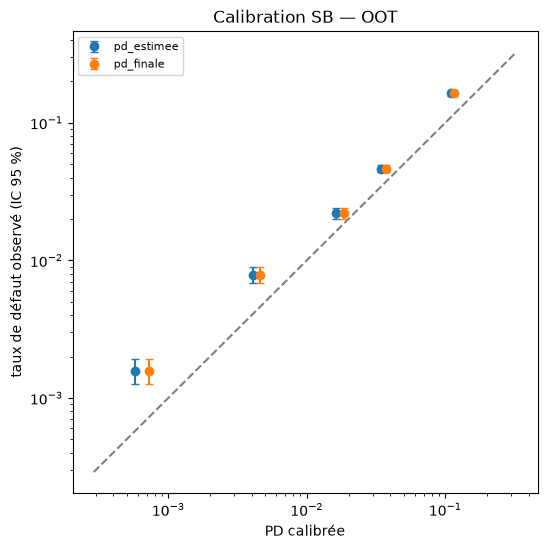

In [11]:
# Cellule 7 — score de Brier & décomposition de Murphy, test de Jeffreys et diagramme de calibration OOT
cal_global, cal_classes = backtesting.backtest_calibration(oot_score, pd_finales, CODE, TARGET)
print("=== Synthèse calibration OOT (Brier & décomposition de Murphy)")
print(cal_global)
print("=== Détail par CHR (OOT vs PD estimée & PD réglementaire)")
print(cal_classes)

calibrage.diagramme_calibration(cal_classes, ("pd_estimee", "pd_finale"), titre=f"Calibration {CODE} — OOT")
plt.show()

## 8. Export des résultats OOT

In [12]:
# Cellule 8 — export de la base OOT scorée (parquet) et du dossier de backtesting (Excel)
Path("outputs/oot").mkdir(parents=True, exist_ok=True)
oot_score.select(
    ID, DATE, TARGET, "segment", "score", "pd_score", "chr", "pd_estimee", "moc_a", "moc_c", "pd_finale", "grade"
).write_parquet(f"data/processed/base_oot_score_{CODE}.parquet")

exploration.exporter_excel({
    f"{CODE}_Perimetre_OOT": suivi_oot["perimetre"],
    f"{CODE}_Segments_OOT": suivi_oot["segments"],
    f"{CODE}_Discrimination": disc_globale,
    f"{CODE}_Cascade_OOT": cascade_oot,
    f"{CODE}_Intra_CHR_OOT": intra_chr_oot,
    f"{CODE}_Mensuel_OOT": disc_mensuelle,
    f"{CODE}_PSI_CHR": psi_detail,
    f"{CODE}_CSI_Variables": csi_synthese,
    f"{CODE}_CSI_Detail": csi_detail,
    f"{CODE}_CHR_OOT": table_oot,
    f"{CODE}_Heterogeneite_OOT": chrm.heterogeneite_chr(table_oot),
    f"{CODE}_Calibration_Glob": cal_global,
    f"{CODE}_Calibration_CHR": cal_classes,
}, f"outputs/oot/backtesting_oot_{CODE}.xlsx")
print(f"Export terminé : outputs/oot/backtesting_oot_{CODE}.xlsx")

Export terminé : outputs/oot/backtesting_oot_SB.xlsx
